# Aprendizagem Supervisionada Aplicada

## IPV/ESTGL 2025/2026
## Mestrado em Controlo de Gestão e Ciência de Dados

##### Professor: Ricardo Gama 
##### Trabalho realizado por: Hélder Vieira 23678

## Análise e Previsão de Atrasos em Voos Comerciais com Recurso a Algoritmos de Regressão

### Notebook 2 - Pré-processamento, Modelação e Avaliação

Este notebook tem como objetivo preparar os dados, construir modelos de regressão e avaliar o desempenho dos algoritmos de Aprendizagem Supervisionada na previsão do tempo de entrega.

### Importação das Bibliotecas

Nesta secção são importadas as bibliotecas necessárias para leitura dos dados, pré-processamento, construção dos modelos e avaliação dos resultados.

In [1]:
# =========================
# Manipulação de Dados
# =========================
import pandas as pd
import numpy as np

# =========================
# Visualização
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# =========================
# Pré-processamento
# =========================
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# =========================
# Modelos de Regressão
# =========================
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)

from lightgbm import LGBMRegressor

# =========================
# Métricas de Avaliação
# =========================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================
# Configurações Gerais
# =========================
import warnings
warnings.filterwarnings("ignore")

### Leitura do Dataset

Nesta secção será realizado o carregamento do dataset utilizado na construção dos modelos de Aprendizagem Supervisionada.

In [2]:
# Carregar dataset tratado do Notebook 1
flights = pd.read_csv("flights_processed.csv")

flights.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print(flights.shape)

(5819079, 31)


O dataset carregado corresponde ao conjunto de voos após limpeza e preparação dos dados.

A próxima etapa consiste em definir a variável alvo do problema de regressão.

## Conversão de Horários para Minutos

In [4]:
for col in ['SCHEDULED_DEPARTURE', 'SCHEDULED_ARRIVAL']:
    hours = flights[col] // 100
    minutes = flights[col] % 100
    flights[col] = hours * 60 + minutes

As variáveis de horário encontravam-se no formato HHMM (ex.: 0930 representa 09:30).

Para facilitar a modelação, estes horários foram convertidos para minutos decorridos desde a meia-noite, garantindo consistência com outras variáveis temporais do dataset, como os atrasos, que já se encontram em minutos.

## Definição da Variável Alvo

A variável alvo escolhida é `ARRIVAL_DELAY`, correspondente ao atraso à chegada em minutos.

Vamos reduzir o número de observações usadas na modelação para tornar o notebook mais rápido. A amostra será aleatória e reprodutível, usando random_state=42.

In [5]:
target = "ARRIVAL_DELAY"

flights_model = flights.dropna(subset=[target]).copy()

SAMPLE_SIZE = 100000

flights_sample = flights_model.sample(
    n=min(SAMPLE_SIZE, len(flights_model)),
    random_state=42
)

print("Dimensão dataset:", flights_sample.shape)

Dimensão dataset: (100000, 31)


Esta etapa permite trabalhar com uma parte representativa dos dados, reduzindo o tempo de treino dos modelos. A amostragem é feita de forma aleatória, mas com random_state=42, garantindo que os resultados podem ser reproduzidos.

## Seleção de Variáveis

Nesta etapa são removidas variáveis que podem introduzir **data leakage**, ou seja, informação que não estaria disponível no momento da previsão e que poderia enviesar os resultados do modelo.

Desta forma, garante-se que os modelos aprendem apenas com variáveis relevantes e disponíveis antes da chegada do voo.

In [6]:
columns_to_drop = [
    "ARRIVAL_DELAY",

    "DEPARTURE_TIME",
    "DEPARTURE_DELAY",
    "TAXI_OUT",
    "WHEELS_OFF",
    "ELAPSED_TIME",
    "AIR_TIME",
    "WHEELS_ON",
    "TAXI_IN",

    "DIVERTED",
    "CANCELLED",
    "CANCELLATION_REASON"
]
X = flights_sample.drop(columns=columns_to_drop)
y = flights_sample[target]

print(X.shape)
print(y.shape)

(100000, 19)
(100000,)


In [7]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (100000, 19)
Target: (100000,)


## Divisão dos Dados em Treino e Teste

Os dados serão divididos em conjunto de treino e conjunto de teste.

O conjunto de treino será utilizado para ajustar os modelos, enquanto o conjunto de teste será usado para avaliar a sua capacidade de generalização.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80000, 19)
X_test: (20000, 19)
y_train: (80000,)
y_test: (20000,)


## Pré-processamento dos Dados

Nesta etapa serão identificadas as variáveis numéricas e categóricas.

As variáveis numéricas serão normalizadas com `StandardScaler`.

As variáveis categóricas serão transformadas através de `OneHotEncoder`, permitindo que sejam utilizadas pelos modelos de regressão.

In [9]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()

for col in categorical_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

print("Variáveis numéricas:")
print(numerical_cols)

print("\nVariáveis categóricas:")
print(categorical_cols)

Variáveis numéricas:
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER', 'SCHEDULED_DEPARTURE', 'SCHEDULED_TIME', 'DISTANCE', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

Variáveis categóricas:
['AIRLINE', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']


In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        )
    ]
)

Foi utilizado um `ColumnTransformer` para aplicar diferentes transformações às variáveis numéricas e categóricas.

Nas variáveis numéricas, valores em falta foram substituídos pela mediana e os dados foram normalizados com `StandardScaler`. Nas variáveis categóricas, valores em falta foram preenchidos com a categoria mais frequente e posteriormente convertidos para formato numérico através de `OneHotEncoder`.

## Definição dos Modelos de Regressão

Serão utilizados diferentes algoritmos de regressão supervisionada, permitindo comparar modelos estatísticos, modelos baseados em árvores de decisão e métodos ensemble.

Os modelos selecionados foram:

- **Baseline Regressor** — modelo de referência que prevê sempre a média da variável alvo
- **Linear Regression** — modelo linear utilizado como baseline estatística para comparação
- **Decision Tree Regressor** — modelo não linear baseado em regras de decisão
- **Random Forest Regressor** — ensemble de múltiplas árvores de decisão
- **Extra Trees Regressor** — variante do Random Forest com maior aleatoriedade
- **Gradient Boosting Regressor** — método ensemble baseado em boosting sequencial
- **LightGBM Regressor** — algoritmo de gradient boosting baseado em árvores de decisão, otimizado para alta eficiência computacional e desempenho em grandes conjuntos de dados
- 
A comparação entre estes modelos permitirá identificar qual apresenta melhor capacidade preditiva na estimativa do atraso de chegada dos voos.

In [11]:
models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=50,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=50,
        learning_rate=0.1,
        random_state=42
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=-1,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
}

## Treino e Avaliação dos Modelos

Nesta etapa, cada modelo será treinado com os dados de treino e avaliado com os dados de teste.

Para avaliar o desempenho dos modelos serão utilizadas as seguintes métricas:

- **MAE (Mean Absolute Error)**: erro médio absoluto
- **MSE (Mean Squared Error)**: erro quadrático médio
- **RMSE (Root Mean Squared Error)**: raiz quadrada do MSE
- **R²**: proporção da variância explicada pelo modelo

In [12]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Modelo": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="RMSE")
results_df

,Modelo,MAE,MSE,RMSE,R2
6,LightGBM,6.741868,98.966515,9.948192,0.930626
3,Random Forest,7.320894,104.996929,10.246801,0.926399
1,Linear Regression,8.691737,115.697850,10.756293,0.918898
4,Extra Trees,8.014842,116.008601,10.770729,0.918680
5,Gradient Boosting,7.974136,118.125952,10.868576,0.917196
2,Decision Tree,8.057768,121.569069,11.025836,0.914782
0,Baseline,20.949126,1426.681785,37.771441,-0.000078


## Comparação dos Modelos por MAE

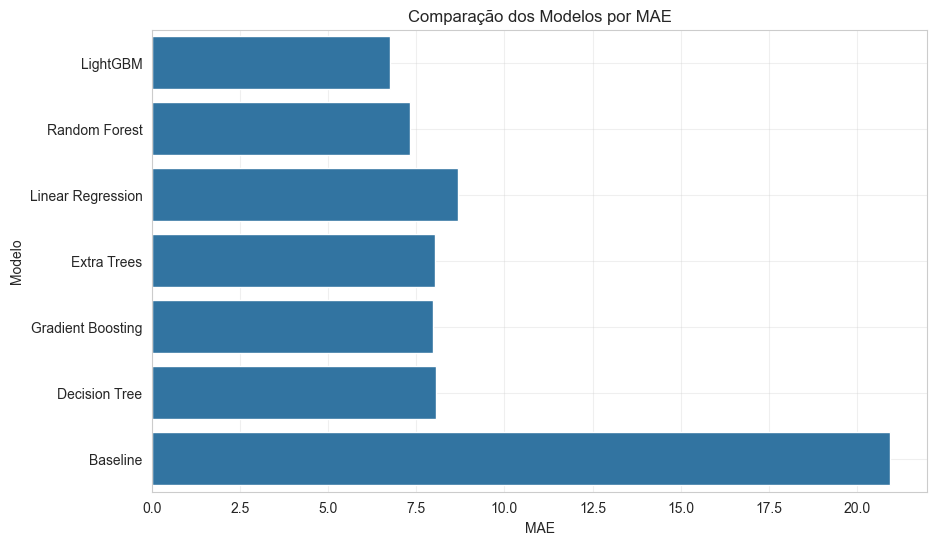

In [13]:
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x="MAE", y="Modelo")
plt.title("Comparação dos Modelos por MAE")
plt.xlabel("MAE")
plt.ylabel("Modelo")
plt.grid(alpha=0.3)
plt.show()

O gráfico apresenta a comparação dos modelos com base no **MAE (Mean Absolute Error)**.

Esta métrica representa o erro médio absoluto entre os valores reais e os valores previstos, permitindo medir a magnitude média do erro sem considerar a sua direção.

Valores mais baixos de MAE indicam melhor desempenho, uma vez que significam menor desvio médio entre previsões e observações reais.

## Comparação dos Modelos por MSE

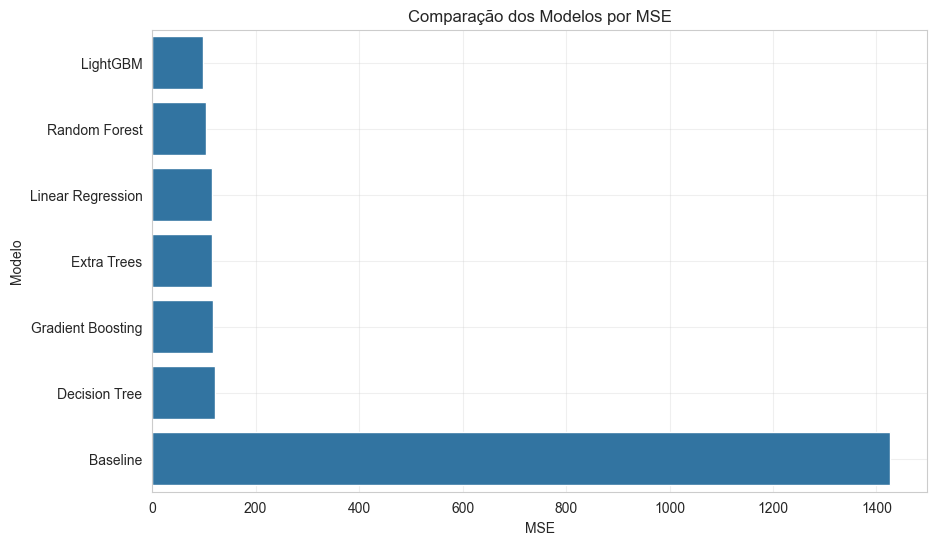

In [14]:
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x="MSE", y="Modelo")
plt.title("Comparação dos Modelos por MSE")
plt.xlabel("MSE")
plt.ylabel("Modelo")
plt.grid(alpha=0.3)
plt.show()

O gráfico compara os modelos com base no **MSE (Mean Squared Error)**.

Esta métrica calcula a média dos erros ao quadrado, penalizando mais fortemente previsões com erros elevados.

Por atribuir maior peso a grandes desvios, o MSE é particularmente útil para identificar modelos mais sensíveis a outliers ou atrasos extremos.

## Comparação dos Modelos por RMSE

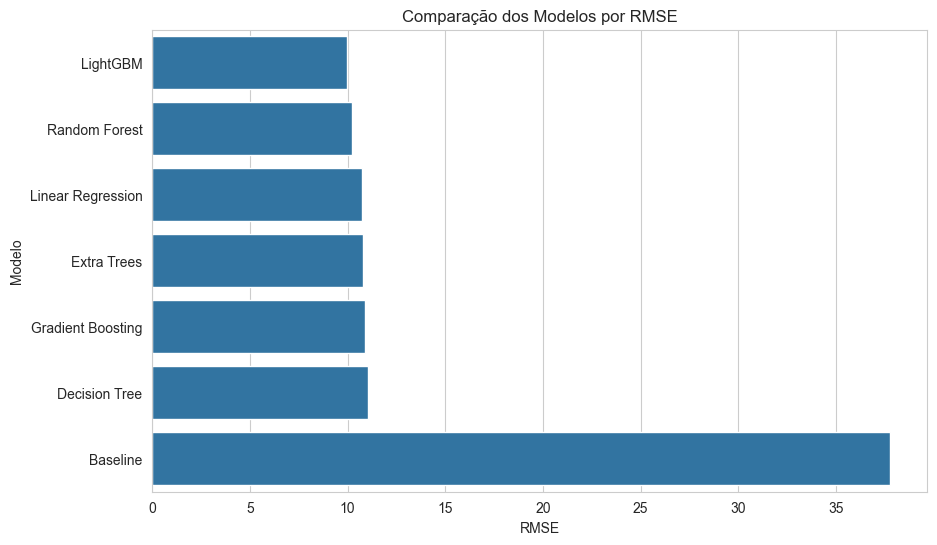

In [15]:
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x="RMSE", y="Modelo")
plt.title("Comparação dos Modelos por RMSE")
plt.xlabel("RMSE")
plt.ylabel("Modelo")
plt.show()

O gráfico apresenta a comparação do desempenho dos diferentes modelos de regressão com base na métrica **RMSE (Root Mean Squared Error)**.

O RMSE mede o erro médio entre os valores reais e os valores previstos, penalizando mais fortemente erros de maior magnitude. Assim, **quanto menor for o valor de RMSE, melhor é a capacidade preditiva do modelo**.

A análise visual permite identificar rapidamente quais os modelos com melhor desempenho na previsão do atraso de chegada dos voos. Modelos baseados em ensemble, como Random Forest, Extra Trees e Gradient Boosting, tendem a capturar relações mais complexas entre as variáveis, podendo apresentar melhores resultados relativamente a modelos mais simples, como a Regressão Linear ou o modelo Baseline.

Esta comparação permite selecionar o modelo mais adequado para a fase final de avaliação e interpretação.

## Comparação dos Modelos por R²

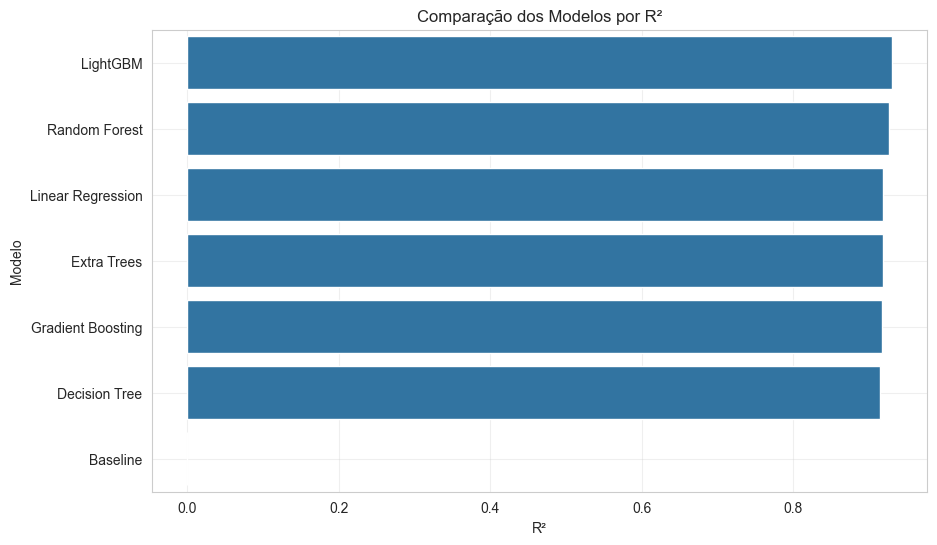

In [16]:
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x="R2", y="Modelo")
plt.title("Comparação dos Modelos por R²")
plt.xlabel("R²")
plt.ylabel("Modelo")
plt.grid(alpha=0.3)
plt.show()

O gráfico apresenta o desempenho dos modelos através do **coeficiente de determinação (R²)**.

Esta métrica mede a proporção da variabilidade da variável alvo explicada pelo modelo.

Valores mais próximos de 1 indicam melhor capacidade explicativa, enquanto valores próximos de 0 ou negativos sugerem fraco desempenho preditivo.

## Valores Reais vs Valores Previstos por Modelo

Os gráficos seguintes comparam os valores reais e previstos para cada modelo de regressão.

Quanto mais próximos os pontos estiverem da linha diagonal vermelha, maior será a precisão das previsões.

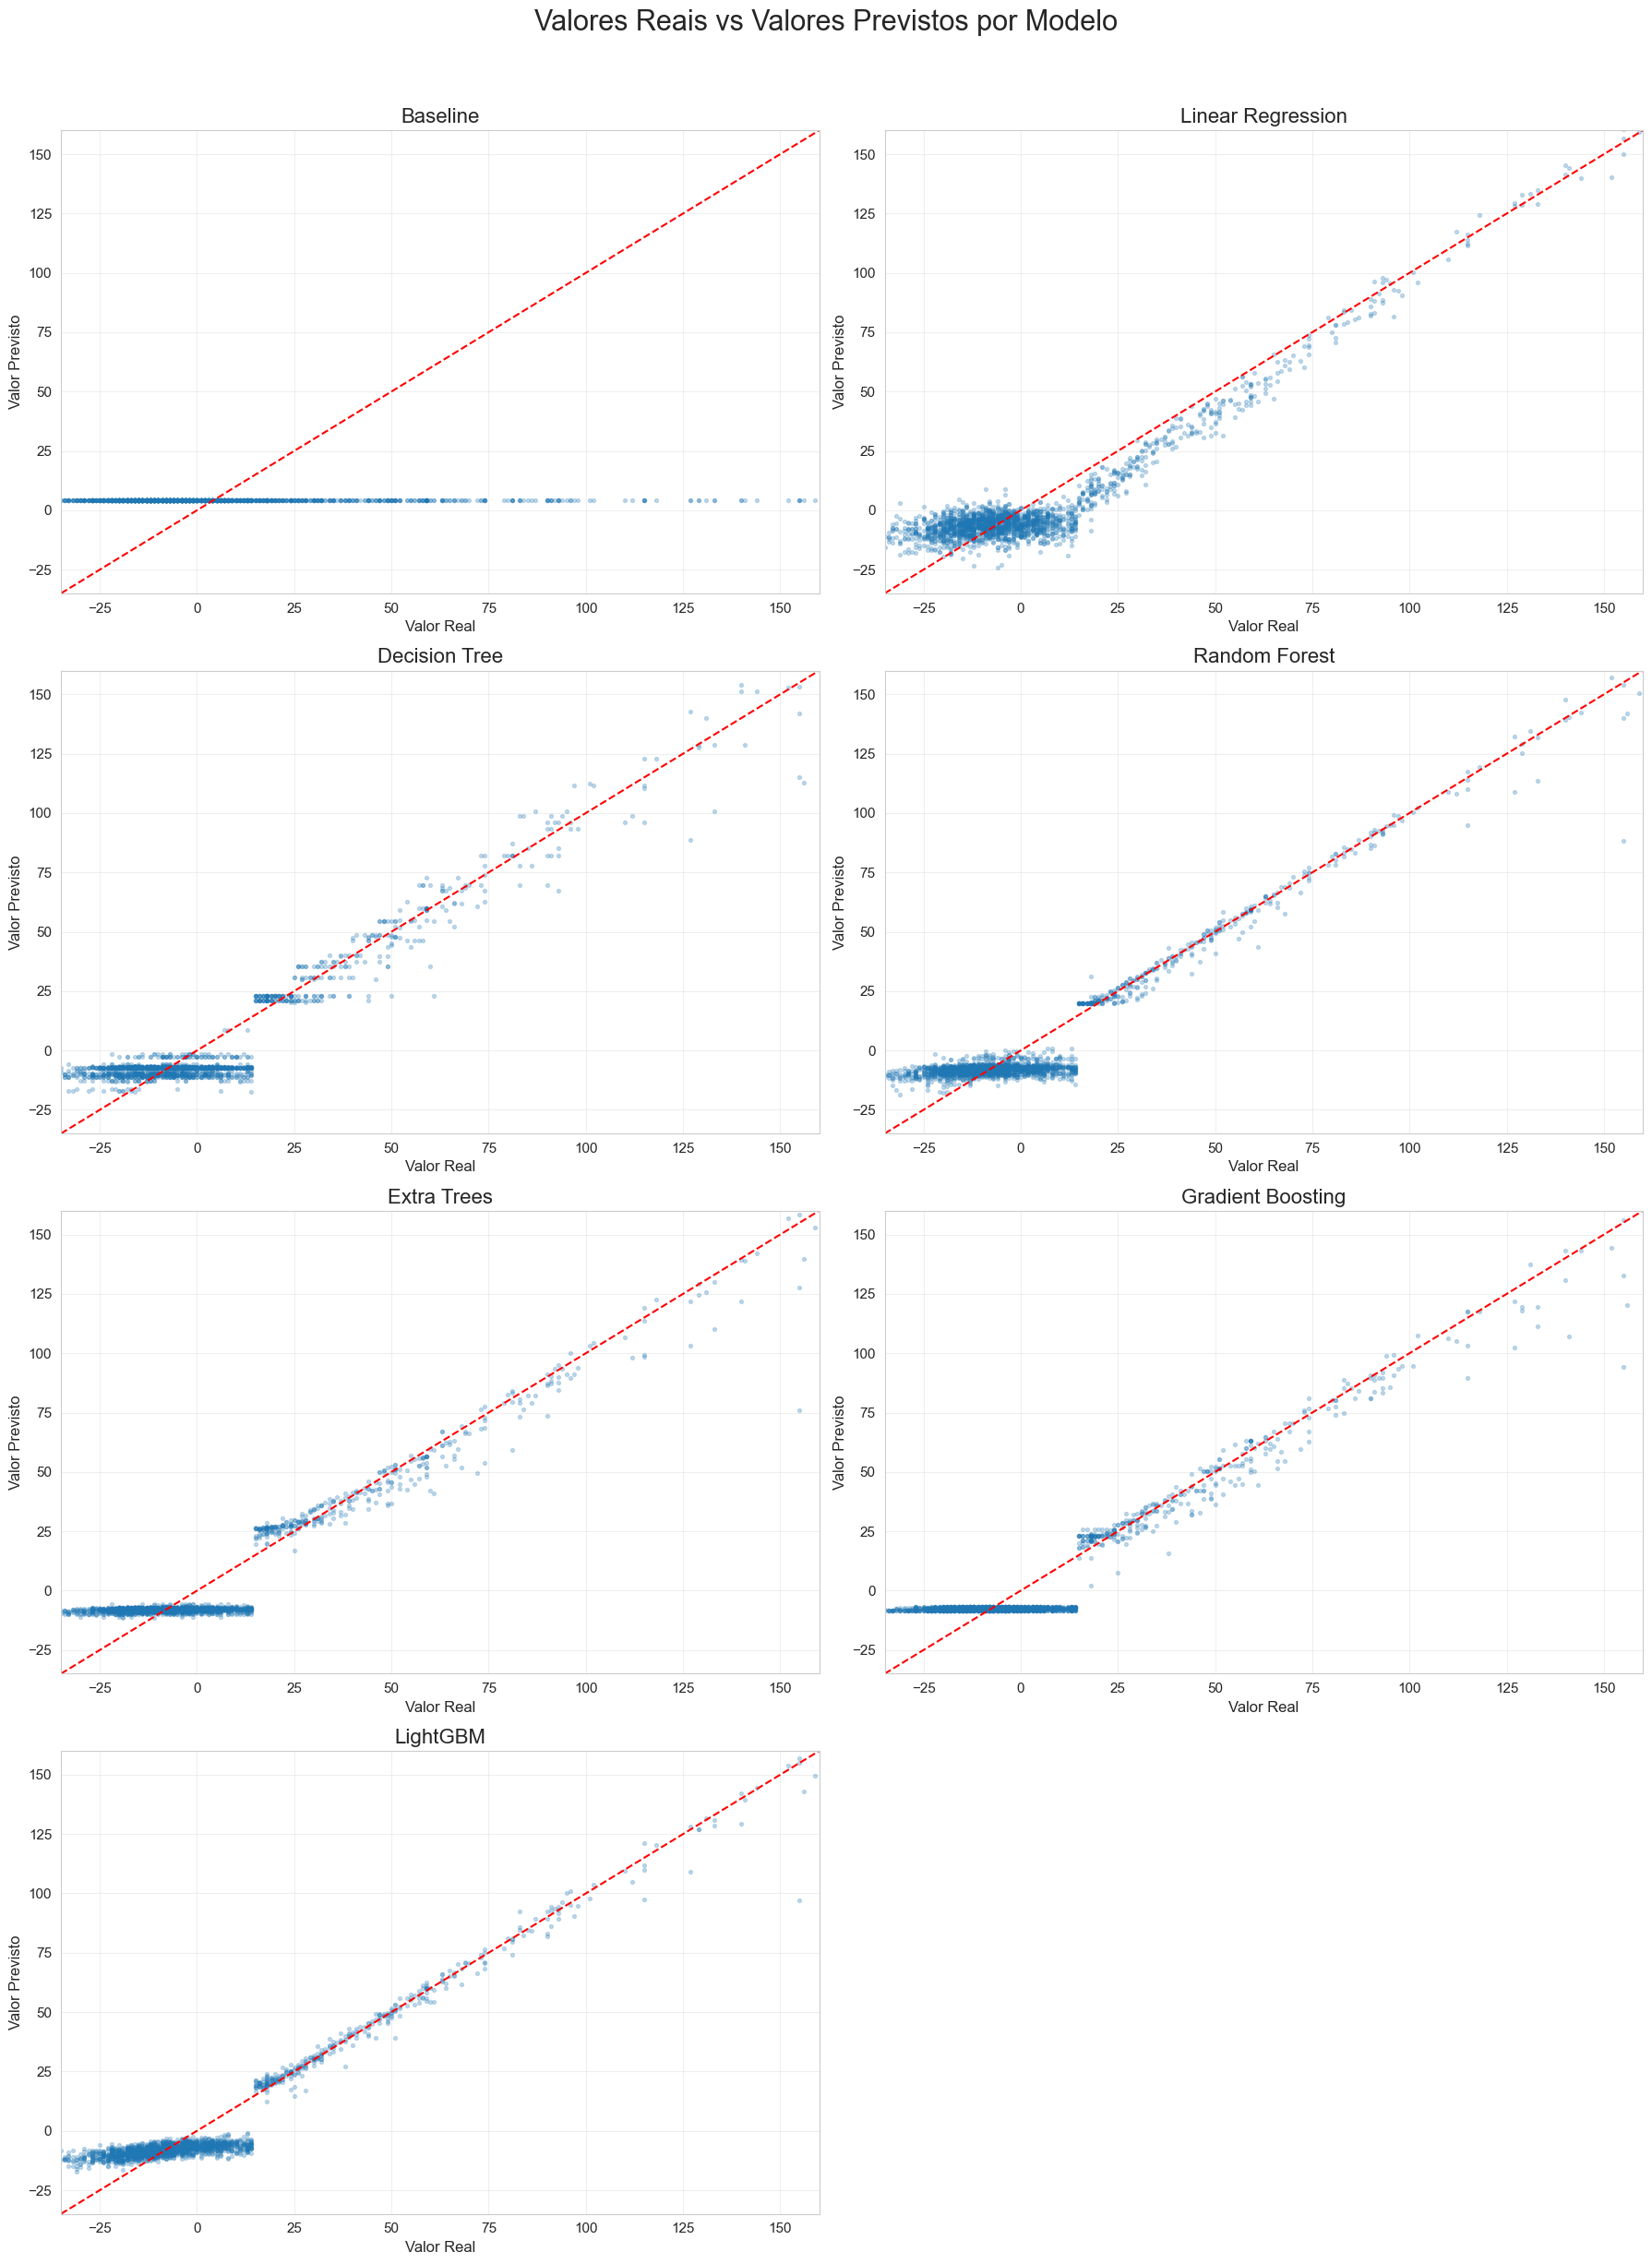

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(18, 24))
axes = axes.flatten()

sample_size = min(2000, len(X_test))
sample_idx = np.random.choice(len(X_test), sample_size, replace=False)

lower = np.percentile(y_test, 1)
upper = np.percentile(y_test, 99)

for i, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)

    y_real_sample = y_test.iloc[sample_idx]
    y_pred_sample = np.array(y_pred)[sample_idx]

    axes[i].scatter(
        y_real_sample,
        y_pred_sample,
        alpha=0.25,
        s=8
    )

    axes[i].plot(
        [lower, upper],
        [lower, upper],
        'r--',
        linewidth=1.5
    )

    axes[i].set_xlim(lower, upper)
    axes[i].set_ylim(lower, upper)

    axes[i].set_title(name, fontsize=16)
    axes[i].set_xlabel("Valor Real", fontsize=12)
    axes[i].set_ylabel("Valor Previsto", fontsize=12)
    axes[i].tick_params(axis="both", labelsize=11)
    axes[i].grid(alpha=0.3)

# esconder subplot vazio
for j in range(len(trained_models), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Valores Reais vs Valores Previstos por Modelo", fontsize=22, y=1.02)
plt.tight_layout()
plt.show()

Os gráficos de dispersão apresentados permitem comparar, para cada modelo, os valores reais de atraso de chegada com os valores previstos.

A linha diagonal vermelha representa o cenário ideal, em que as previsões coincidem exatamente com os valores observados. Assim, quanto mais próximos os pontos estiverem desta linha, maior será a capacidade preditiva do modelo.

A dispersão dos pontos evidencia também a dificuldade dos modelos em prever atrasos extremos, particularmente em casos de valores muito elevados, onde tende a existir maior erro de previsão.

## Variáveis com Maior Influência no Modelo

Esta análise permite identificar quais as variáveis que mais influenciam as previsões realizadas pelos modelos baseados em árvores.

Quanto maior o valor de importância atribuído a uma variável, maior o seu contributo para a capacidade preditiva do modelo. Desta forma, é possível compreender melhor quais os fatores mais relevantes na previsão do atraso de chegada dos voos.

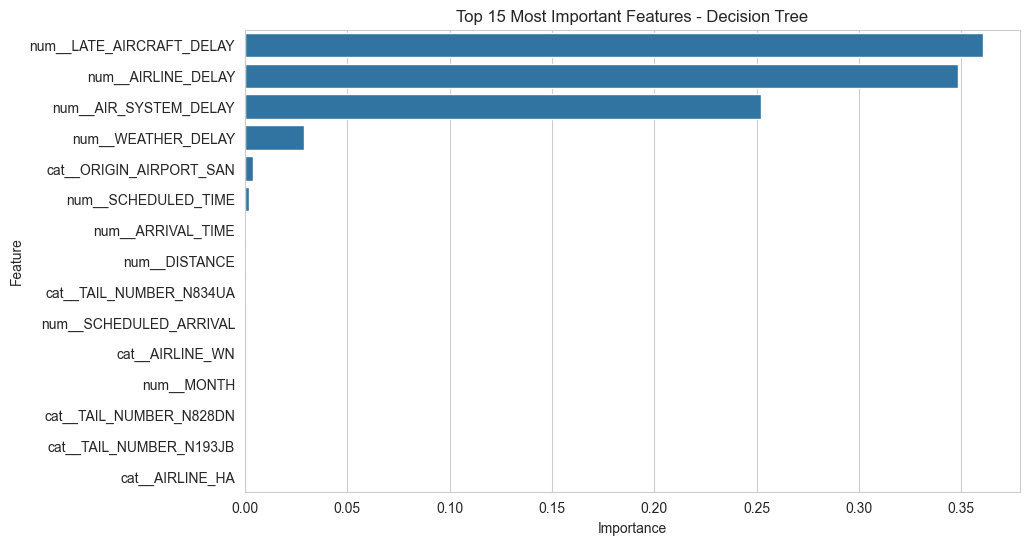

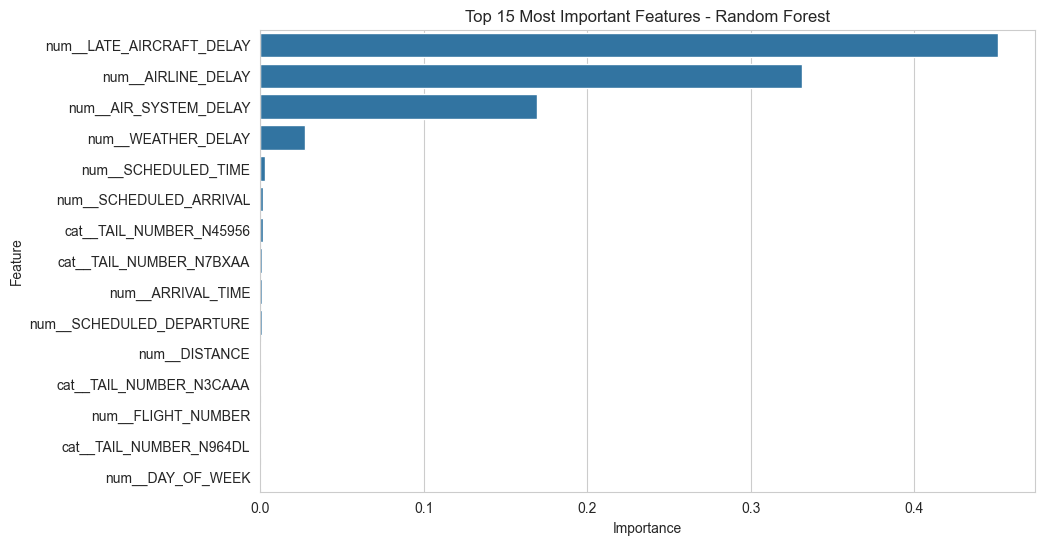

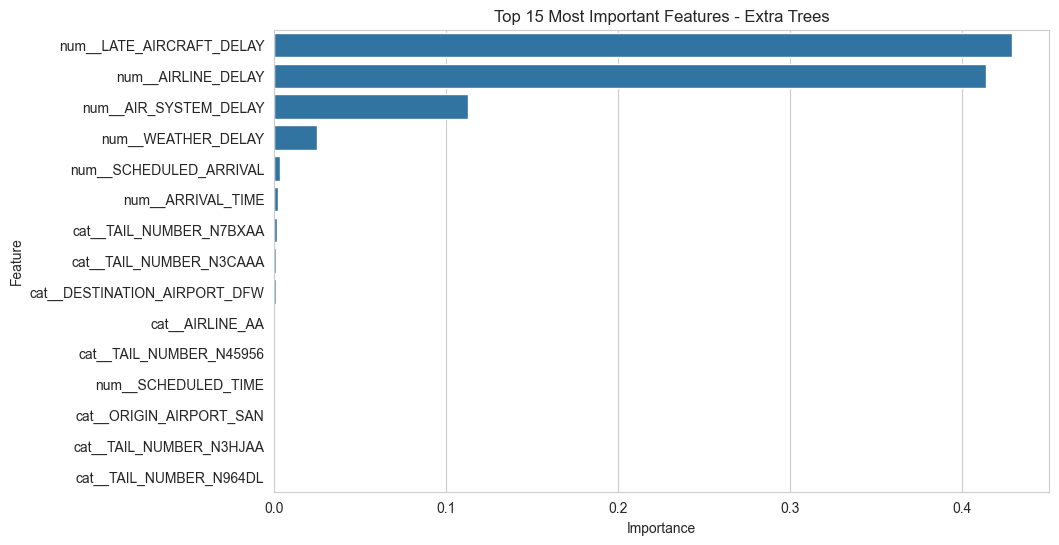

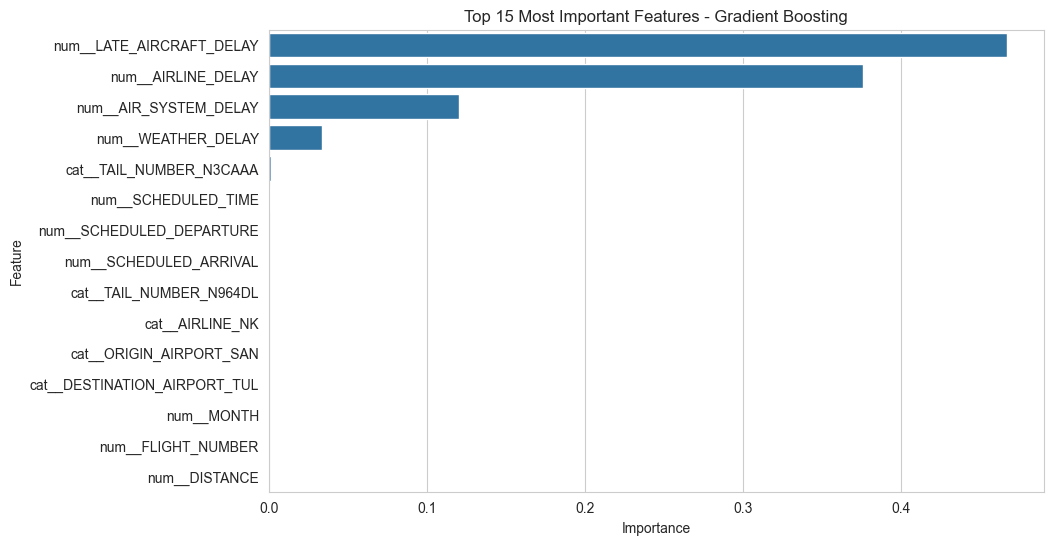

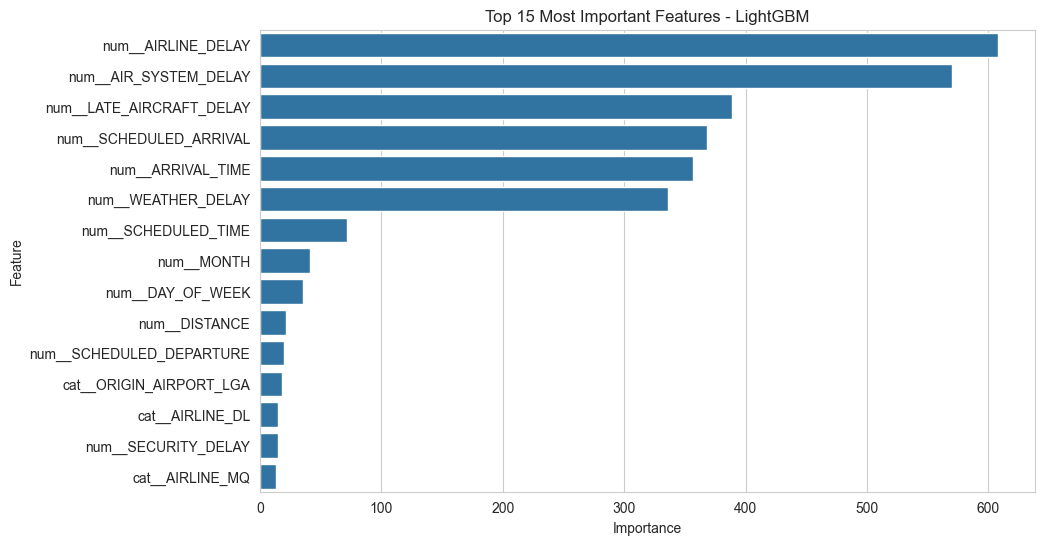

In [18]:
tree_models = [
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "LightGBM"
]

for model_name in tree_models:
    if model_name in trained_models:
        model_pipeline = trained_models[model_name]

        feature_names = model_pipeline.named_steps["preprocessor"].get_feature_names_out()
        importances = model_pipeline.named_steps["model"].feature_importances_

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False).head(15)

        plt.figure(figsize=(10, 6))
        sns.barplot(data=importance_df, x="Importance", y="Feature")
        plt.title(f"Top 15 Most Important Features - {model_name}")
        plt.xlabel("Importance")
        plt.ylabel("Feature")
        plt.show()

A importância das variáveis foi analisada nos modelos baseados em árvores, permitindo identificar quais os atributos com maior influência nas previsões.

## Distribuição dos Erros de Previsão por Modelo

Os gráficos seguintes apresentam a distribuição dos erros de previsão para cada modelo treinado.

Esta análise permite comparar se os modelos tendem a sobrestimar ou subestimar os atrasos de chegada. Distribuições mais concentradas em torno de zero indicam melhor desempenho preditivo.

In [19]:
best_model = trained_models["Random Forest"]

y_pred = best_model.predict(X_test)

residuals = y_test - y_pred

lower = np.percentile(residuals, 1)
upper = np.percentile(residuals, 99)

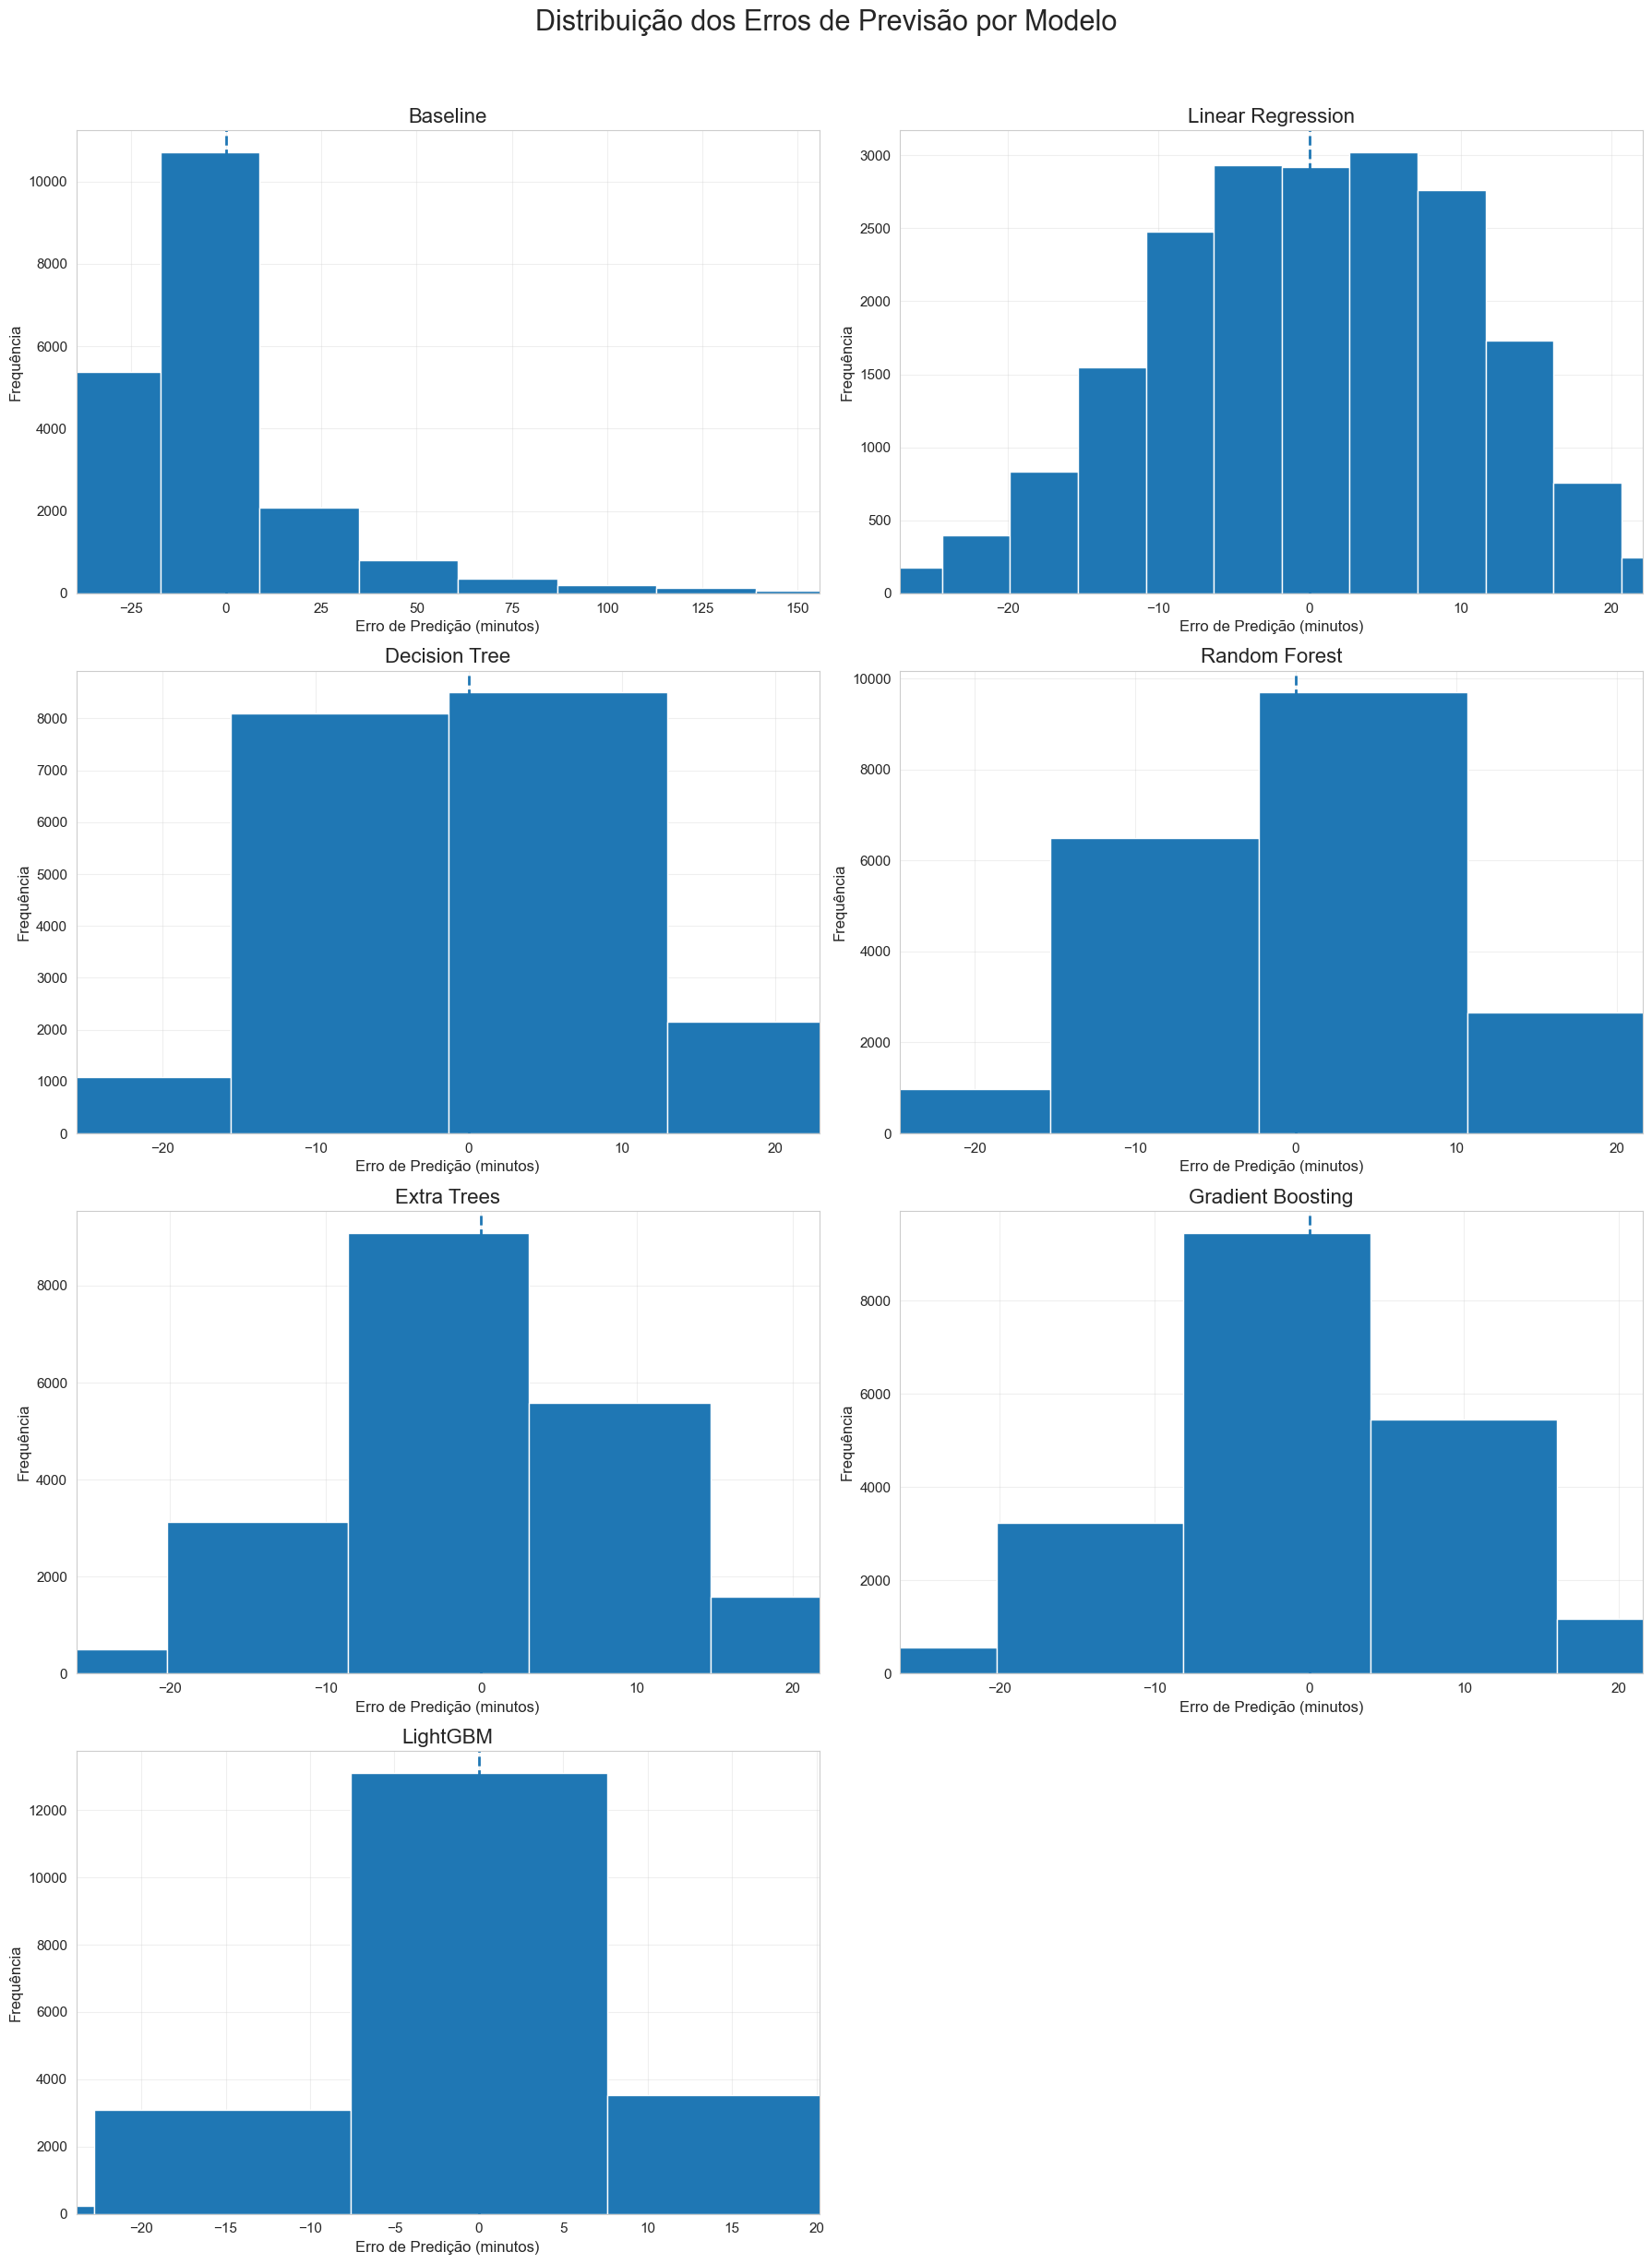

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(18, 24))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    lower = np.percentile(residuals, 1)
    upper = np.percentile(residuals, 99)

    axes[i].hist(residuals, bins=40)
    axes[i].axvline(0, linestyle="--", linewidth=2)
    axes[i].set_xlim(lower, upper)

    axes[i].set_title(name, fontsize=16)
    axes[i].set_xlabel("Erro de Predição (minutos)", fontsize=12)
    axes[i].set_ylabel("Frequência", fontsize=12)
    axes[i].tick_params(axis='both', labelsize=11)
    axes[i].grid(alpha=0.3)

# esconder último subplot vazio
for j in range(len(trained_models), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribuição dos Erros de Previsão por Modelo", fontsize=22, y=1.02)
plt.tight_layout()
plt.show()


De forma geral, erros mais concentrados em torno de zero indicam melhor desempenho preditivo. Observa-se que os modelos **Random Forest** e **LightGBM** apresentam as distribuições mais compactas, evidenciando maior precisão na previsão dos atrasos.

Por outro lado, o modelo **Baseline** apresenta a distribuição mais dispersa, confirmando ser o menos eficaz na tarefa de previsão.

## Conclusão

Neste trabalho foi desenvolvido um conjunto de modelos de regressão com o objetivo de prever o atraso de chegada de voos (`ARRIVAL_DELAY`) com base em variáveis operacionais e temporais associadas a cada voo.

Após a preparação e transformação dos dados, foram treinados e comparados diferentes modelos de machine learning, incluindo abordagens lineares e modelos baseados em árvores. A avaliação foi realizada recorrendo às métricas MAE, MSE, RMSE e R², complementadas por análises visuais como scatter plots, distribuição dos erros de previsão e importância das variáveis.

Os resultados obtidos demonstraram que os modelos baseados em ensembles, como o **Random Forest** e o **LightGBM**, apresentaram melhor desempenho preditivo, superando modelos mais simples como a Regressão Linear e o modelo Baseline. A análise da importância das variáveis mostrou ainda que fatores relacionados com atrasos operacionais e condições de voo tiveram maior influência na previsão do atraso de chegada.

Apesar dos bons resultados obtidos, a previsão de atrasos extremos continua a representar um desafio, refletindo a natureza complexa e parcialmente imprevisível do tráfego aéreo. Como trabalho futuro, poderiam ser exploradas técnicas de otimização de hiperparâmetros, validação cruzada e a integração de dados externos, como condições meteorológicas em tempo real.